# 02: Consumption model

**Question:** can we predict a house's monthly units?

We test every model the honest way: **leave one house out**. The model trains on all houses except one, then predicts the house it has never seen. We repeat this for every house.

- **MAE** = average error in units per month (lower is better)
- **R²** = how much of the up and down the model explains (1 = perfect, 0 = no better than a flat average, below 0 = worse)

In [1]:
import sys
sys.path.append("../ml-service")

import pandas as pd
import matplotlib.pyplot as plt
from core.data import build_clean
from core.train import evaluate, evaluate_seasonal, SMALL_FEATURES, MEDIUM_FEATURES, SEASONAL_BASE_TEMPS

df = build_clean()
print("Houses:", df["site_id"].nunique(), "| Months:", len(df))

Houses: 4 | Months: 52


## Attempt 1: one model for all houses

The plan was: with fewer than 5 houses, use Linear Regression on temperature and sanctioned load.

In [2]:
rows = []
for name, feats in [("LinearRegression", SMALL_FEATURES), ("Ridge", MEDIUM_FEATURES)]:
    r = evaluate(name, feats, df)
    rows.append({"model": name, "features": ", ".join(feats), "MAE": r["mae"], "R2": r["r2"], **r["mae_per_house"]})
pd.DataFrame(rows)

,model,features,MAE,R2,H004,H005,H006,H007
0,LinearRegression,"avg_temp, sanctioned_load_kw",443.0,-1.180,1301.8,200.7,149.0,120.3
1,Ridge,"avg_temp, sanctioned_load_kw, ac_total, house_...",288.5,0.069,770.6,171.4,96.0,116.3


**Result: this does not work yet.** H004 (44 marla, 13 ACs) uses about 5 times more than the other houses. When it is left out, the model has only seen small houses and cannot guess a house that big. With 4 houses, there is simply not enough variety. This model will improve as more houses come in.

## Attempt 2: learn the shape of the year

Every house has its own level (big house, small house), but the **shape** of the year is similar: more units when it is hot.

So we divide each month by the house's own average:

`ratio = units / house average`

and learn `ratio = a + b × temperature` from all houses together. In the app the user uploads a bill, so we know their average, and the model fills in the shape.

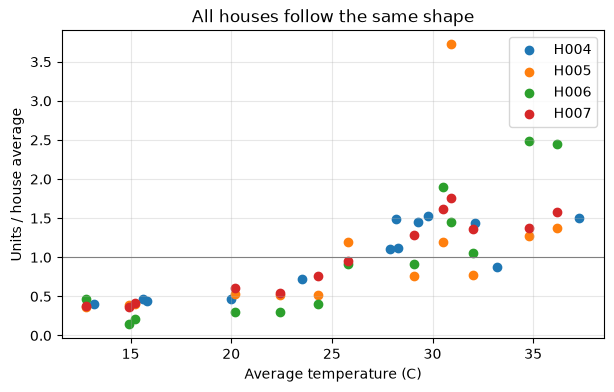

In [3]:
d = df.copy()
d["house_mean"] = d.groupby("site_id")["units"].transform("mean")
d["ratio"] = d["units"] / d["house_mean"]

fig, ax = plt.subplots(figsize=(7, 4))
for site, g in d.groupby("site_id"):
    ax.scatter(g["avg_temp"], g["ratio"], label=site)
ax.set_xlabel("Average temperature (C)")
ax.set_ylabel("Units / house average")
ax.set_title("All houses follow the same shape")
ax.axhline(1, color="grey", lw=0.8)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [4]:
s = evaluate_seasonal(df)
print("MAE:", s["mae"], "units | R2:", s["r2"])
print("Error per house:", s["mae_per_house"])

from sklearn.linear_model import LinearRegression
m = LinearRegression().fit(d[["avg_temp"]], d["ratio"])
print(f"\nratio = {m.intercept_:.3f} + {m.coef_[0]:.4f} x temperature")
print(f"Every 1 C hotter adds about {m.coef_[0]*100:.1f}% of the house's average monthly units.")

MAE: 113.2 units | R2: 0.858
Error per house: {'H004': 236.5, 'H005': 111.4, 'H006': 69.7, 'H007': 35.4}

ratio = -0.707 + 0.0672 x temperature
Every 1 C hotter adds about 6.7% of the house's average monthly units.


### Predicted vs real, for houses the model never saw

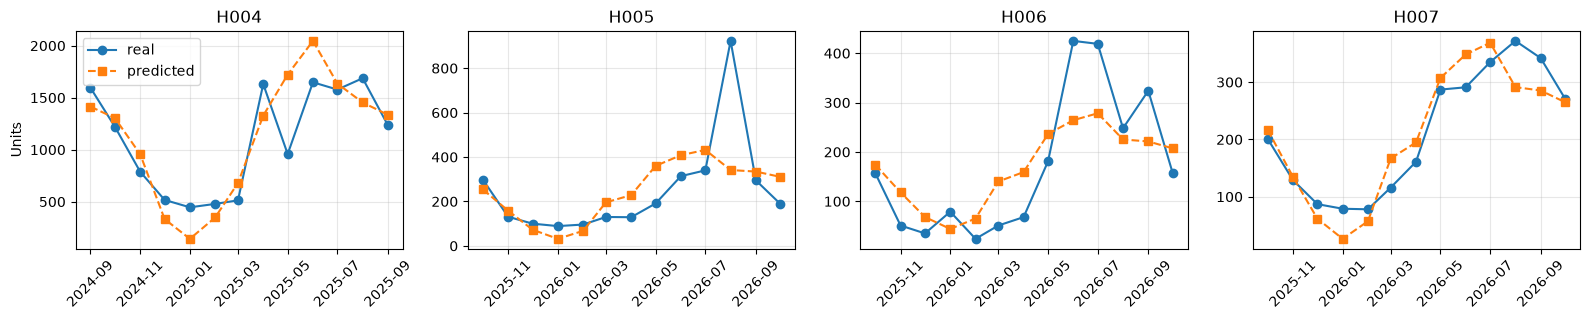

In [5]:
d["pred"] = s["predictions"]
d["bill_date"] = pd.to_datetime(dict(year=d["year"], month=d["month"], day=1))
sites = sorted(d["site_id"].unique())
fig, axes = plt.subplots(1, len(sites), figsize=(4 * len(sites), 3.3))
for ax, site in zip(axes, sites):
    g = d[d["site_id"] == site].sort_values("bill_date")
    ax.plot(g["bill_date"], g["units"], "o-", label="real")
    ax.plot(g["bill_date"], g["pred"], "s--", label="predicted")
    ax.set_title(site)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Units")
axes[0].legend()
plt.tight_layout()
plt.show()

## Attempt 3: only count the heat above a base temperature

Use is nearly flat in winter and mild months and climbs once ACs switch on. So instead of a straight line in temperature, we try `ratio = a + b × (degrees above T0)`, where degrees below T0 count as zero ("cooling degrees"). `retrain()` tries each T0 and keeps the one with the lowest error on unseen homes.

In [6]:
rows = []
for b in SEASONAL_BASE_TEMPS:
    r = evaluate_seasonal(df, b)
    rows.append({"shape": "straight line" if b is None else f"degrees above {b} C",
                 "MAE (units)": r["mae"], "R2": r["r2"], "avg % error": round(100 * r["mape"], 1)})
pd.DataFrame(rows)

,shape,MAE (units),R2,avg % error
0,straight line,113.2,0.858,41.1
1,degrees above 18 C,106.3,0.848,35.1
2,degrees above 20 C,103.6,0.841,33.0
3,degrees above 22 C,106.4,0.825,34.6


**Result:** "degrees above 20°C" has the lowest error (104 vs 113 units; 33% vs 41% average error), with R² 0.84 instead of 0.86. The error matters more for the app, so `retrain()` picks it. Every 1°C above 20°C adds about 9% of a home's average monthly units.

## With and without the unusual month

H005's August 2026 bill (923 units) is real but unusual (the AC ran much more). We test both ways.

In [7]:
rows = []
for drop in (False, True):
    dd = build_clean(drop_outliers=drop)
    s2 = evaluate_seasonal(dd, 20)
    l2 = evaluate("LinearRegression", SMALL_FEATURES, dd)
    rows.append({"unusual month": "removed" if drop else "kept",
                 "shape model MAE": s2["mae"], "shape model R2": s2["r2"],
                 "one-model MAE": l2["mae"], "one-model R2": l2["r2"]})
pd.DataFrame(rows)

,unusual month,shape model MAE,shape model R2,one-model MAE,one-model R2
0,kept,103.6,0.841,443.0,-1.180
1,removed,85.3,0.878,338.2,-0.288


## Summary

| Model | Used when | Result with 4 houses |
|---|---|---|
| Shape model (`ratio = a + b × degrees above 20°C`) | User uploads a bill | Good: R² 0.84, average error 104 units |
| One model for all houses | User has no bill | Not reliable yet; needs more houses |

`retrain()` (in `ml-service/core/train.py`) trains both after every new bill and keeps a new model only if it scores better. Every run is logged in `models/history.csv`, which gives the "accuracy vs number of houses" chart later.